[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_06/MFM_ch6_fr_bias/MFM_ch6_fr_bias.ipynb)

# MFM_ch6_fr_bias

How much volatility alone raises a measured correlation: rho_c = rho sqrt((1+delta)/(1+delta rho^2)) for three calm-period correlations (constant beta), with the 2008 S&P 500 variance ratio marked.

*Modelling Financial Markets (MFM), Chapter 6: Multivariate Volatility and Dependence. Author: Daniel Traian Pele.*

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import networkx as nx
from scipy import stats, optimize, integrate
from scipy.signal import lfilter
from scipy.special import gammaln
try:
    from arch import arch_model
except ImportError:                      # Colab: pip install arch
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'], check=True)
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [2]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
FAM_COL = {'gaussian': MainBlue, 't': IDAred, 'clayton': Forest, 'gumbel': Amber, 'frank': Purple}

SIDE = (5.6, 3.5)   # size of the charts placed next to text

SEED = 42
NUM = {}
TABLE_DIR = '.'


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def shade_crises(ax, alpha=0.5):
    for a, b in (('2008-09-15', '2009-03-31'), ('2020-02-20', '2020-04-30'), ('2022-01-03', '2022-10-31')):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=BandBlue, alpha=alpha, lw=0)

## Data

In [3]:
import os
import numpy as np
import pandas as pd

REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, price field, label, start date)
ASSETS = {
    'spy':   ('SPY.US',        'adjusted_close', 'SPY (S&P 500 ETF)',          '2002-07-30'),
    'tlt':   ('TLT.US',        'adjusted_close', 'TLT (20+y Treasury ETF)',    '2002-07-30'),
    'ief':   ('IEF.US',        'adjusted_close', 'IEF (7-10y Treasury ETF)',   '2002-07-30'),
    'sp500': ('GSPC.INDX',     'close',          'S&P 500',                    '2000-01-01'),
    'stoxx': ('STOXX50E.INDX', 'close',          'Euro Stoxx 50',              '2000-01-01'),
    'bet':   ('BET',           'close',          'BET (Romania)',              '2000-01-01'),
    'bettr': ('BETTR.INDX',    'close',          'BET-TR (Romania)',           '2014-09-23'),
    'btc':   ('BTC-USD.CC',    'close',          'Bitcoin',                    '2014-09-17'),
    'vix':   ('VIX.INDX',      'close',          'VIX',                        '2000-01-01'),
    'jpm':   ('JPM.US',        'adjusted_close', 'JPMorgan Chase',             '2010-01-01'),
    'bac':   ('BAC.US',        'adjusted_close', 'Bank of America',            '2010-01-01'),
    'dbk':   ('DBK.XETRA',     'adjusted_close', 'Deutsche Bank',              '2010-01-01'),
    'bnp':   ('BNP.PA',        'adjusted_close', 'BNP Paribas',                '2010-01-01'),
    'tlv':   ('TLV.RO',        'adjusted_close', 'Banca Transilvania',         '2010-01-01'),
    'brd':   ('BRD.RO',        'adjusted_close', 'BRD-Groupe Societe Generale', '2010-01-01'),
}
# US-listed ETFs for the COVOL case study (Engle and Campos-Martins, 2023, Section 9)
COVOL_ETFS = ['XLB', 'XLC', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLRE', 'XLU', 'XLV', 'XLY',
              'IWF', 'IWD', 'IWM', 'EFA', 'EEM', 'GLD', 'TLT', 'LQD', 'USO']
for _e in COVOL_ETFS:
    ASSETS['etf_' + _e.lower()] = (f'{_e}.US', 'adjusted_close', _e, '1999-12-31')
LABELS = {k: v[2] for k, v in ASSETS.items()}
SHORT = {'spy': 'SPY', 'tlt': 'TLT', 'ief': 'IEF', 'sp500': 'S&P 500', 'stoxx': 'Euro Stoxx 50', 'bet': 'BET',
         'bettr': 'BET-TR', 'btc': 'Bitcoin', 'vix': 'VIX', 'jpm': 'JPM', 'bac': 'BAC', 'dbk': 'DBK', 'bnp': 'BNP',
         'tlv': 'TLV', 'brd': 'BRD'}
BANKS = ['jpm', 'bac', 'dbk', 'bnp', 'tlv', 'brd']


def read_market(symbol):
    """Daily series of one asset from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def load_price(name, start=None, end=END):
    """Daily price, cleaned with the conventions of the chapter."""
    symbol, col, _, start0 = ASSETS[name]
    d = read_market(symbol).loc[start or start0:end]
    d = d[d[col] > 0].dropna(subset=[col])
    s = d[col]
    if name != 'btc':
        keep = s.index.dayofweek < 5                                   # no weekend quotes
        vol = d['volume'].fillna(0) if 'volume' in d else pd.Series(0.0, index=d.index)
        keep &= ~((s.diff() == 0) & (vol <= 0)).values                # holidays: unchanged price AND zero volume
        s = s[keep]                                                    # (trading days with volume and an unchanged price stay)
    return s.rename(name)


def joint_prices(names, start=None, end=END):
    """Prices of the assets on their common trading days."""
    return pd.concat([load_price(n, start, end) for n in names], axis=1, join='inner').dropna()


def joint_returns(names, start=None, end=END):
    """Daily log returns, computed AFTER aligning the prices on common days."""
    return np.log(joint_prices(names, start, end)).diff().dropna()


def weekly_returns(names, start=None, end=END):
    """Weekly log returns: the last common price of each week (Friday), then differences."""
    p = joint_prices(names, start, end)
    return np.log(p.resample('W-FRI').last()).diff().dropna()

## Dependence tools: EWMA, GARCH, DCC, Forbes-Rigobon, copulas

In [4]:
import numpy as np
import pandas as pd
from scipy import stats, optimize, integrate
from scipy.signal import lfilter
from scipy.special import gammaln
from arch import arch_model
try:
    from numba import njit
except ImportError:                      # without numba the same functions run as plain Python (slower)
    def njit(*args, **kwargs):
        return args[0] if (len(args) == 1 and callable(args[0])) else (lambda f: f)


# =============================================================================
# EWMA and rolling window
# =============================================================================
def ewma_cov(R, lam=0.94, init=100):
    """Sigma_t = lam*Sigma_{t-1} + (1-lam) r_{t-1} r_{t-1}'  (forecast for day t, without r_t).
    The first init observations only initialise the recursion: Sigma_init = their covariance; NaN before init."""
    X = np.asarray(R, dtype=float)
    T, N = X.shape
    S = np.full((T, N, N), np.nan)
    S[init] = np.cov(X[:init].T)
    for t in range(init + 1, T):
        S[t] = lam * S[t - 1] + (1 - lam) * np.outer(X[t - 1], X[t - 1])
    return S


def ewma_corr(R, lam=0.94, i=0, j=1):
    S = ewma_cov(R, lam)
    return pd.Series(S[:, i, j] / np.sqrt(S[:, i, i] * S[:, j, j]), index=R.index)


def rolling_corr(R, window, a=None, b=None):
    a, b = a or R.columns[0], b or R.columns[1]
    return R[a].rolling(window).corr(R[b])


def fisher_ci(rho, n, level=0.95):
    """Confidence interval for a correlation by the Fisher z transformation (i.i.d. data)."""
    z, se = np.arctanh(rho), 1 / np.sqrt(n - 3)
    q = stats.norm.ppf(0.5 + level / 2)
    return np.tanh(z - q * se), np.tanh(z + q * se)


# =============================================================================
# Univariate GARCH(1,1) -- the first step of DCC
# =============================================================================
def garch_filter(r, dist='normal'):
    """GARCH(1,1) with constant mean on returns in percent (QML).
    Returns the parameters, the conditional volatility (%) and the standardised residuals."""
    res = arch_model(100 * r, mean='Constant', vol='GARCH', p=1, q=1, dist=dist).fit(disp='off')
    z = (res.resid / res.conditional_volatility).rename(r.name)
    return res.params, res.conditional_volatility.rename(r.name), z, res.loglikelihood


def garch_all(R, dist='normal'):
    out = {c: garch_filter(R[c], dist) for c in R.columns}
    Z = pd.concat([out[c][2] for c in R.columns], axis=1)
    V = pd.concat([out[c][1] for c in R.columns], axis=1)
    P = pd.DataFrame({c: out[c][0] for c in R.columns})
    ll = sum(out[c][3] for c in R.columns)
    return P, V, Z, ll


# =============================================================================
# DCC (Engle, 2002): Q_t = (1-a-b) Qbar + a z_{t-1} z_{t-1}' + b Q_{t-1}
# =============================================================================
def dcc_path(Z, a, b, Qbar=None):
    """Correlation matrices R_t (T x N x N). Each element of Q_t follows a linear recursion,
    computed in vectorised form with lfilter."""
    X = np.asarray(Z, dtype=float)
    T, N = X.shape
    Qbar = np.cov(X.T, bias=True) if Qbar is None else Qbar
    P = np.einsum('ti,tj->tij', X, X)                  # z_t z_t'
    drive = np.empty_like(P)
    drive[0] = Qbar
    drive[1:] = (1 - a - b) * Qbar + a * P[:-1]         # input at time t: uses z_{t-1}
    Q = lfilter([1.0], [1.0, -b], drive.reshape(T, -1), axis=0).reshape(T, N, N)
    Q[0] = Qbar
    d = np.sqrt(np.einsum('tii->ti', Q))
    return Q / (d[:, :, None] * d[:, None, :])


@njit(cache=True)
def dcc2_corr_loglik(x, y, a, b, q11b, q22b, q12b):
    """Bivariate case of dcc_corr_loglik, written as a single loop (same recursion as dcc_path)."""
    q11, q22, q12 = q11b, q22b, q12b
    c = 1.0 - a - b
    ll = 0.0
    for t in range(len(x)):
        r = q12 / np.sqrt(q11 * q22)
        d = 1.0 - r * r
        ll += -0.5 * (np.log(d) + (x[t] * x[t] + y[t] * y[t] - 2.0 * r * x[t] * y[t]) / d - x[t] * x[t] - y[t] * y[t])
        q11 = c * q11b + a * x[t] * x[t] + b * q11
        q22 = c * q22b + a * y[t] * y[t] + b * q22
        q12 = c * q12b + a * x[t] * y[t] + b * q12
    return ll


def dcc_corr_loglik(Z, a, b, Qbar=None):
    """Correlation part of the log-likelihood: -1/2 sum(log|R_t| + z'R_t^{-1}z - z'z)."""
    X = np.asarray(Z, dtype=float)
    if X.shape[1] == 2:
        Q = np.cov(X.T, bias=True) if Qbar is None else Qbar
        return dcc2_corr_loglik(np.ascontiguousarray(X[:, 0]), np.ascontiguousarray(X[:, 1]), float(a), float(b),
                                Q[0, 0], Q[1, 1], Q[0, 1])
    R = dcc_path(X, a, b, Qbar)
    sign, logdet = np.linalg.slogdet(R)
    quad = np.einsum('ti,tij,tj->t', X, np.linalg.inv(R), X)
    return -0.5 * np.sum(logdet + quad - np.sum(X ** 2, axis=1))


def ccc_loglik(Z):
    """CCC (Bollerslev, 1990): constant correlation = DCC with a = b = 0."""
    return dcc_corr_loglik(Z, 0.0, 0.0)


def _num_hessian(f, x, h=1e-4):
    k = len(x)
    H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            e_i, e_j = np.eye(k)[i] * h, np.eye(k)[j] * h
            H[i, j] = (f(x + e_i + e_j) - f(x + e_i - e_j) - f(x - e_i + e_j) + f(x - e_i - e_j)) / (4 * h * h)
    return H


def dcc_fit(Z, start=(0.03, 0.95), Qbar=None):
    """Step 2 of DCC: (a, b) by maximum likelihood, with Qbar fixed at the sample covariance of standardised residuals
    (correlation targeting), or at the given Qbar (a bootstrap with a fixed target). The standard errors come from the
    step-2 Hessian (they ignore the step-1 error)."""
    X = np.asarray(Z, dtype=float)
    Qbar = np.cov(X.T, bias=True) if Qbar is None else np.asarray(Qbar, dtype=float)

    def nll(p):
        a, b = p
        if a < 0 or b < 0 or a + b >= 0.9999:
            return 1e10
        return -dcc_corr_loglik(X, a, b, Qbar)

    best = None
    for s in (start, (0.01, 0.98), (0.05, 0.90), (0.10, 0.80)):
        r = optimize.minimize(nll, s, method='Nelder-Mead', options=dict(xatol=1e-7, fatol=1e-7, maxiter=4000))
        if best is None or r.fun < best.fun:
            best = r
    a, b = best.x
    try:
        H = _num_hessian(lambda p: -nll(p), best.x)
        se = np.sqrt(np.diag(np.linalg.inv(-H)))
    except Exception:
        se = np.array([np.nan, np.nan])
    return dict(a=a, b=b, se_a=se[0], se_b=se[1], loglik=-best.fun, Qbar=Qbar,
                R=dcc_path(X, a, b, Qbar), ccc_loglik=ccc_loglik(X))


# =============================================================================
# Forbes-Rigobon (2002)
# =============================================================================
def fr_adjust(rho_c, delta):
    """Crisis correlation adjusted for the rise in the variance of the source market:
    rho* = rho_c / sqrt(1 + delta (1 - rho_c^2)), delta = Var_crisis/Var_calm - 1."""
    return rho_c / np.sqrt(1 + delta * (1 - rho_c ** 2))


def fr_inflation(rho, delta):
    """Crisis correlation from a calm-period correlation rho when only the source-market variance rises (constant beta): rho sqrt((1+delta)/(1+delta rho^2))."""
    return rho * np.sqrt((1 + delta) / (1 + delta * rho ** 2))


def fisher_z_test(rho1, n1, rho0, n0):
    """H0: rho1 <= rho0 (one-sided test, independent samples)."""
    z = (np.arctanh(rho1) - np.arctanh(rho0)) / np.sqrt(1 / (n1 - 3) + 1 / (n0 - 3))
    return z, 1 - stats.norm.cdf(z)


def crisis_table(ret2, source, targets, calm, crisis):
    """Calm vs crisis correlation, the Forbes-Rigobon adjustment and the Fisher z test for several markets."""
    rows = []
    c0, c1 = ret2.loc[calm[0]:calm[1]], ret2.loc[crisis[0]:crisis[1]]
    delta = c1[source].var() / c0[source].var() - 1
    for tg in targets:
        r0, r1 = c0[source].corr(c0[tg]), c1[source].corr(c1[tg])
        adj = fr_adjust(r1, delta)
        n0, n1 = len(c0) // 2, len(c1) // 2          # overlapping 2-day returns: effective n ~ n/2
        rows.append(dict(target=tg, rho_calm=r0, rho_crisis=r1, delta=delta, rho_adj=adj,
                         z_raw=fisher_z_test(r1, n1, r0, n0)[0], p_raw=fisher_z_test(r1, n1, r0, n0)[1],
                         z_adj=fisher_z_test(adj, n1, r0, n0)[0], p_adj=fisher_z_test(adj, n1, r0, n0)[1],
                         n_calm=len(c0), n_crisis=len(c1)))
    return pd.DataFrame(rows).set_index('target')


def exceedance_corr(x, y, qs):
    """Exceedance correlation (Longin-Solnik, 2001): corr(x, y | x<q_x, y<q_y) for lower tails and
    corr(x, y | x>q_x, y>q_y) for upper tails, at the same marginal quantiles."""
    out = []
    for q in qs:
        lo = (x <= np.quantile(x, q)) & (y <= np.quantile(y, q))
        hi = (x >= np.quantile(x, 1 - q)) & (y >= np.quantile(y, 1 - q))
        out.append((q, np.corrcoef(x[lo], y[lo])[0, 1] if lo.sum() > 5 else np.nan, lo.sum(),
                    np.corrcoef(x[hi], y[hi])[0, 1] if hi.sum() > 5 else np.nan, hi.sum()))
    return pd.DataFrame(out, columns=['q', 'rho_low', 'n_low', 'rho_high', 'n_high']).set_index('q')


# =============================================================================
# Bivariate copulas
# =============================================================================
FAMILIES = ['gaussian', 't', 'clayton', 'gumbel', 'frank']
FAM_LABEL = {'gaussian': 'Gaussian', 't': 'Student t', 'clayton': 'Clayton', 'gumbel': 'Gumbel', 'frank': 'Frank'}
EPS = 1e-10


def pseudo_obs(X):
    """Pseudo-observations: rank / (n + 1), column by column."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([stats.rankdata(X[:, k]) / (len(X) + 1) for k in range(X.shape[1])])


def kendall_tau(u, v):
    return stats.kendalltau(u, v)[0]


def spearman_rho(u, v):
    return stats.spearmanr(u, v)[0]


def _debye1(x):
    if abs(x) < 1e-8:
        return 1.0
    val = integrate.quad(lambda t: t / np.expm1(t), 0, abs(x))[0] / abs(x)
    return val if x > 0 else val + abs(x) / 2


def tau_of(fam, theta):
    """Kendall's tau implied by the copula parameter."""
    if fam in ('gaussian', 't'):
        return 2 / np.pi * np.arcsin(theta[0] if np.ndim(theta) else theta)
    th = float(np.atleast_1d(theta)[0])
    if fam == 'clayton':
        return th / (th + 2)
    if fam == 'gumbel':
        return 1 - 1 / th
    if fam == 'frank':
        return 1 - 4 / th * (1 - _debye1(th))


def theta_from_tau(fam, tau):
    """Inversion of the tau <-> parameter relation (method of moments on Kendall's tau)."""
    if fam in ('gaussian', 't'):
        return np.sin(np.pi * tau / 2)
    if fam == 'clayton':
        return 2 * tau / (1 - tau)
    if fam == 'gumbel':
        return 1 / (1 - tau)
    if fam == 'frank':
        return optimize.brentq(lambda th: tau_of('frank', th) - tau, 1e-6 if tau > 0 else -60, 60 if tau > 0 else -1e-6)


def tail_dep(fam, par):
    """(lambda_L, lambda_U) for the given parameters."""
    if fam == 'gaussian':
        return 0.0, 0.0
    if fam == 't':
        rho, nu = par
        lam = 2 * stats.t.cdf(-np.sqrt((nu + 1) * (1 - rho) / (1 + rho)), nu + 1)
        return lam, lam
    th = par[0]
    if fam == 'clayton':
        return 2 ** (-1 / th), 0.0
    if fam == 'gumbel':
        return 0.0, 2 - 2 ** (1 / th)
    return 0.0, 0.0


def log_density(fam, par, u, v):
    u = np.clip(u, EPS, 1 - EPS)
    v = np.clip(v, EPS, 1 - EPS)
    if fam == 'gaussian':
        rho = par[0]
        x, y = stats.norm.ppf(u), stats.norm.ppf(v)
        return -0.5 * np.log(1 - rho ** 2) - (rho ** 2 * (x ** 2 + y ** 2) - 2 * rho * x * y) / (2 * (1 - rho ** 2))
    if fam == 't':
        rho, nu = par
        x, y = stats.t.ppf(u, nu), stats.t.ppf(v, nu)
        return (stable_constant(nu) - 0.5 * np.log(1 - rho ** 2)
                - (nu + 2) / 2 * np.log1p((x ** 2 + y ** 2 - 2 * rho * x * y) / (nu * (1 - rho ** 2)))
                + (nu + 1) / 2 * (np.log1p(x ** 2 / nu) + np.log1p(y ** 2 / nu)))
    th = par[0]
    if fam == 'clayton':
        return (np.log1p(th) - (1 + th) * (np.log(u) + np.log(v))
                - (2 + 1 / th) * np.log(u ** -th + v ** -th - 1))
    if fam == 'gumbel':
        lu, lv = -np.log(u), -np.log(v)
        A = lu ** th + lv ** th
        Ath = A ** (1 / th)
        return (-Ath - np.log(u) - np.log(v) + (th - 1) * (np.log(lu) + np.log(lv))
                + (2 / th - 2) * np.log(A) + np.log1p((th - 1) / Ath))
    if fam == 'frank':
        e = -np.expm1(-th)
        den = e - (-np.expm1(-th * u)) * (-np.expm1(-th * v))
        return np.log(th * e) - th * (u + v) - 2 * np.log(np.abs(den))


def h_func(fam, par, u, v):
    """h(v|u) = dC(u,v)/du: the conditional distribution function (Rosenblatt transform)."""
    u = np.clip(u, EPS, 1 - EPS)
    v = np.clip(v, EPS, 1 - EPS)
    if fam == 'gaussian':
        rho = par[0]
        x, y = stats.norm.ppf(u), stats.norm.ppf(v)
        return stats.norm.cdf((y - rho * x) / np.sqrt(1 - rho ** 2))
    if fam == 't':
        rho, nu = par
        x, y = stats.t.ppf(u, nu), stats.t.ppf(v, nu)
        return stats.t.cdf((y - rho * x) / np.sqrt((nu + x ** 2) * (1 - rho ** 2) / (nu + 1)), nu + 1)
    th = par[0]
    if fam == 'clayton':
        return u ** (-th - 1) * (u ** -th + v ** -th - 1) ** (-1 / th - 1)
    if fam == 'gumbel':
        lu, lv = -np.log(u), -np.log(v)
        A = lu ** th + lv ** th
        return np.exp(-A ** (1 / th)) / u * lu ** (th - 1) * A ** (1 / th - 1)
    if fam == 'frank':
        a, b = np.expm1(-th * u), np.expm1(-th * v)
        return (a + 1) * b / (np.expm1(-th) + a * b)


def simulate(fam, par, n, rng):
    """Simulation of n pairs (u, v) from the copula."""
    if fam == 'gaussian':
        rho = par[0]
        z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
        return stats.norm.cdf(z)
    if fam == 't':
        rho, nu = par
        z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
        w = np.sqrt(nu / rng.chisquare(nu, n))
        return stats.t.cdf(z * w[:, None], nu)
    th = par[0]
    if fam == 'clayton':          # Marshall-Olkin with a Gamma(1/theta) frailty
        V = rng.gamma(1 / th, 1, n)
        E = rng.exponential(1, (n, 2))
        return (1 + E / V[:, None]) ** (-1 / th)
    if fam == 'gumbel':           # Marshall-Olkin with a positive stable frailty, alpha = 1/theta (Kanter)
        al = 1 / th
        U = rng.uniform(0, np.pi, n)
        W = rng.exponential(1, n)
        S = np.sin(al * U) / np.sin(U) ** (1 / al) * (np.sin((1 - al) * U) / W) ** ((1 - al) / al)
        E = rng.exponential(1, (n, 2))
        return np.exp(-(E / S[:, None]) ** al)
    if fam == 'frank':            # inverting the h function
        u, w = rng.uniform(size=n), rng.uniform(size=n)
        v = -np.log1p(w * np.expm1(-th) / (w + (1 - w) * np.exp(-th * u))) / th
        return np.column_stack([u, v])


def fit_copula(fam, u, v, diagnostics=None):
    """ML estimation on pseudo-observations (canonical maximum likelihood, CML)."""
    tau = kendall_tau(u, v)
    if fam == 'gaussian':
        par = [_gaussian_rho_mle(u,v,diagnostics)]
    elif fam == 't':
        par = _fit_t_numerically(u,v,tau,diagnostics)
    else:
        lo, hi = {'clayton': (1e-4, 30), 'gumbel': (1.0001, 30), 'frank': (1e-4, 60)}[fam]
        f = lambda p: -np.sum(log_density(fam, [p], u, v))
        th0 = min(max(theta_from_tau(fam, max(tau, 0.02)), lo * 1.01), hi * 0.99)
        r = optimize.minimize_scalar(f, bounds=(lo, hi), method='bounded', options=dict(xatol=1e-7))
        if f(th0) < r.fun:
            r = optimize.minimize_scalar(f, bracket=(lo * 1.01, th0, hi * 0.99), bounds=(lo, hi), method='bounded')
        par = [r.x]
    ll = np.sum(log_density(fam, par, u, v))
    k = 2 if fam == 't' else 1
    lamL, lamU = tail_dep(fam, par)
    return dict(family=fam, par=list(map(float, par)), loglik=float(ll), aic=float(2 * k - 2 * ll),
                bic=float(k * np.log(len(u)) - 2 * ll), tau_model=float(tau_of(fam, par if fam in ('gaussian', 't') else par[0])),
                lamL=float(lamL), lamU=float(lamU))


def cvm_rosenblatt(fam, par, u, v, chunk=1500):
    """S_n^(B) (Genest, Remillard & Beaudoin, 2009): Cramer-von Mises distance between the empirical
    distribution of the Rosenblatt pairs (u, h(v|u)) and the independence copula."""
    E = np.column_stack([u, h_func(fam, par, u, v)])
    n = len(E)
    t1 = n / 9
    t2 = np.sum((1 - E[:, 0] ** 2) * (1 - E[:, 1] ** 2)) / 2
    t3 = 0.0
    for i in range(0, n, chunk):
        Ei = E[i:i + chunk]
        t3 += np.sum((1 - np.maximum(Ei[:, None, 0], E[None, :, 0])) * (1 - np.maximum(Ei[:, None, 1], E[None, :, 1])))
    return t1 - t2 + t3 / n


def gof_test(fam, u, v, B=200, seed=42, fit=None):
    """Goodness-of-fit test with a parametric bootstrap: simulate from the fitted copula, pseudo-observations,
    refit, statistic S_n^(B); p-value = share of bootstrap statistics >= the observed one."""
    fit = fit or fit_copula(fam, u, v)
    s0 = cvm_rosenblatt(fam, fit['par'], u, v)
    rng = np.random.default_rng(seed)
    sb = []
    for _ in range(B):
        X = simulate(fam, fit['par'], len(u), rng)
        U = pseudo_obs(X)
        fb = fit_copula(fam, U[:, 0], U[:, 1])
        sb.append(cvm_rosenblatt(fam, fb['par'], U[:, 0], U[:, 1]))
    sb = np.array(sb)
    return dict(stat=float(s0), p=float((1 + np.sum(sb >= s0)) / (B + 1)), B=B)


def empirical_tail_dep(u, v, q):
    """lambda_L(q) = P(U<=q, V<=q)/q and lambda_U(q) = P(U>1-q, V>1-q)/q."""
    return np.mean((u <= q) & (v <= q)) / q, np.mean((u > 1 - q) & (v > 1 - q)) / q


def stable_constant(nu):
    if nu < 100:
        return gammaln((nu+2)/2)+gammaln(nu/2)-2*gammaln((nu+1)/2)
    h=1/nu; a=nu/2
    if h < 1e-3:
        t=sum((-1)**(k+1)*h**k/(k+1) for k in range(1,7))
    else:t=1-np.log1p(h)/h
    def mu(x):
        inv=1/x
        return inv*(1/12+inv**2*(-1/360+inv**2*(1/1260-inv**2/1680)))
    return t-2*(mu(a+0.5)-mu(a))


def _gaussian_rho_mle(u, v, diagnostics=None):
    if not np.isfinite(u).all() or not np.isfinite(v).all():
        raise ValueError('Copula input must be finite')
    x, y = stats.norm.ppf(np.clip(u, EPS, 1-EPS)), stats.norm.ppf(np.clip(v, EPS, 1-EPS))
    if len(x)==0 or x.shape!=y.shape:
        raise ValueError('Copula inputs must have the same nonempty shape')
    left=float(np.mean((x+y)**2));right=-float(np.mean((x-y)**2))
    if left<=0 or right>=0 or np.all(np.asarray(u)+np.asarray(v)==1):
        raise ValueError('Perfect dependence has no finite Gaussian copula MLE')
    a=float(np.mean(x*x+y*y));b=float(np.mean(x*y))
    def poly(rho):
        if rho == -1:return left
        if rho == 1:return right
        return -rho**3+b*rho**2+(1-a)*rho+b
    cuts=[-1.,1.];disc=b*b+3*(1-a)
    if disc>=0:
        cuts+= [z for z in [(b-np.sqrt(disc))/3,(b+np.sqrt(disc))/3]if -1<z<1]
    cuts=sorted(set(cuts));values=[left if z==-1 else right if z==1 else poly(z)for z in cuts]
    roots=[z for z,vv in zip(cuts,values)if -1<z<1 and vv==0]
    for lo,hi,fl,fh in zip(cuts[:-1],cuts[1:],values[:-1],values[1:]):
        if fl*fh<0:roots.append(optimize.brentq(poly,lo,hi,xtol=1e-14,rtol=4*np.finfo(float).eps))
    candidates=[(float(log_density('gaussian',[z],u,v).sum()),z)for z in roots if -1<z<1]
    candidates=[x for x in candidates if np.isfinite(x[0])]
    if not candidates:raise RuntimeError('No finite Gaussian copula maximum found')
    best=max(candidates,key=lambda x:x[0])
    if diagnostics is not None:diagnostics.append(dict(candidates=candidates,near_tie=sum(abs(z[0]-best[0])<=1e-10 for z in candidates)>1))
    return best[1]


def _fit_t_numerically(u,v,tau,diagnostics=None):
    def objective(p):
        with np.errstate(over='ignore',invalid='ignore',divide='ignore'):
            rho=float(np.tanh(p[0]));nu=float(2.01+np.exp(p[1]))
            if not np.isfinite(rho) or not np.isfinite(nu) or abs(rho)>=1 or nu<=2.01:return np.inf
            value=-float(log_density('t',[rho,nu],u,v).sum())
        return value if np.isfinite(value) else np.inf
    diagnostic_offset=len(diagnostics) if diagnostics is not None else 0
    runs=[]
    for nu0 in (3,6,15):
        x0=[np.arctanh(np.sin(np.pi*tau/2)),np.log(nu0-2.01)]
        z=optimize.minimize(objective,x0,method='Nelder-Mead',options=dict(xatol=1e-6,fatol=1e-6,maxfev=4000,maxiter=4000))
        runs.append(z)
        if diagnostics is not None:diagnostics.append(dict(start_nu=nu0,success=bool(z.success),status=int(z.status),fun=float(z.fun) if np.isfinite(z.fun) else None,finite_objective=bool(np.isfinite(z.fun)),x=[float(v) if np.isfinite(v) else None for v in z.x],finite_parameters=bool(np.isfinite(z.x).all()),nfev=int(z.nfev),nit=int(z.nit)))
    valid=[z for z in runs if z.success and np.isfinite(z.fun)]
    if not valid:raise RuntimeError('No converged finite t-copula fit; bootstrap must stop')
    best=min(valid,key=lambda z:z.fun)
    if any(np.isfinite(z.fun) and z.fun<best.fun-1e-8 for z in runs if not z.success):
        raise RuntimeError('Unconverged t start has a better objective; bootstrap must stop')
    par=[float(np.tanh(best.x[0])),float(2.01+np.exp(best.x[1]))]
    if diagnostics is not None:
        selected=next(i for i,z in enumerate(runs) if z is best)
        diagnostics[diagnostic_offset+selected].update(selected=True,one_minus_abs_rho=1-abs(par[0]),nu_minus_lower=par[1]-2.01,log_nu_minus_lower=float(best.x[1]))
    rho_g=_gaussian_rho_mle(u,v);ll_g=float(log_density('gaussian',[rho_g],u,v).sum())
    if -best.fun < ll_g-1e-6:raise RuntimeError('t likelihood is below Gaussian closure; bootstrap must stop')
    return par

## Helper functions

In [5]:
CALM08, CRISIS08 = ('2007-09-14', '2008-09-12'), ('2008-09-15', '2009-03-31')
CALM20, CRISIS20 = ('2019-02-19', '2020-02-19'), ('2020-02-20', '2020-04-30')

## Analysis

In [6]:
def two_day_returns(names, start='2006-01-01', end='2021-12-31'):
    """2-day returns (moving sum, as in Forbes-Rigobon): log p_t - log p_{t-2}, from common prices."""
    lp = np.log(joint_prices(names, start=start, end=end))
    return (lp - lp.shift(2)).dropna()


def fig_forbes_rigobon():
    r2 = two_day_returns(['sp500', 'stoxx', 'bet'])
    t = crisis_table(r2, 'sp500', ['stoxx', 'bet'], CALM08, CRISIS08)
    t.to_csv(os.path.join(TABLE_DIR, 'ch6_forbes_rigobon_2008.csv'), float_format='%.6g')
    fig, ax = plt.subplots(figsize=SIDE)
    x = np.arange(len(t))
    ax.bar(x - 0.26, t['rho_calm'], 0.24, color=Forest, label='Calm year before (Sep 2007 - Sep 2008)')
    ax.bar(x, t['rho_crisis'], 0.24, color=IDAred, label='Crisis (15 Sep 2008 - 31 Mar 2009), raw')
    ax.bar(x + 0.26, t['rho_adj'], 0.24, color=MainBlue, label='Crisis, Forbes-Rigobon adjusted')
    ax.set_xticks(x)
    ax.set_xticklabels([f'S&P 500 / {SHORT[k]}' for k in t.index])
    ax.set_ylabel('Correlation of 2-day returns')
    legend_outside_bottom(ax, ncol=1, y=-0.1)
    save_fig('ch6_forbes_rigobon')
    for k in t.index:
        for c in ('rho_calm', 'rho_crisis', 'rho_adj', 'z_raw', 'p_raw', 'z_adj', 'p_adj'):
            NUM[f'fr_{k}_{c}'] = t.loc[k, c]
    NUM.update(fr_delta=t['delta'].iloc[0], fr_n_calm=int(t['n_calm'].iloc[0]), fr_n_crisis=int(t['n_crisis'].iloc[0]),
               fr_vr=1 + t['delta'].iloc[0])
    return t


def fig_fr_bias():
    delta = np.linspace(0, 10, 201)
    fig, ax = plt.subplots(figsize=SIDE)
    for rho, c in ((0.2, Forest), (0.4, MainBlue), (0.6, IDAred)):
        ax.plot(delta, fr_inflation(rho, delta), color=c, lw=1.5, label=f'calm-period correlation {rho}')
        ax.axhline(rho, color=c, lw=0.6, ls=':')
    ax.axvline(NUM['fr_delta'], color=Gray, ls='--', lw=0.9, label=f'S&P 500 in 2008: delta = {NUM["fr_delta"]:.1f}')
    ax.set_xlabel('delta = Var(crisis) / Var(calm) - 1 for the source market')
    ax.set_ylabel('Measured crisis correlation')
    legend_outside_bottom(ax, ncol=2, y=-0.18)
    save_fig('ch6_fr_bias')
    NUM.update(frb_04=fr_inflation(0.4, NUM['fr_delta']), frb_02=fr_inflation(0.2, NUM['fr_delta']))

## Run

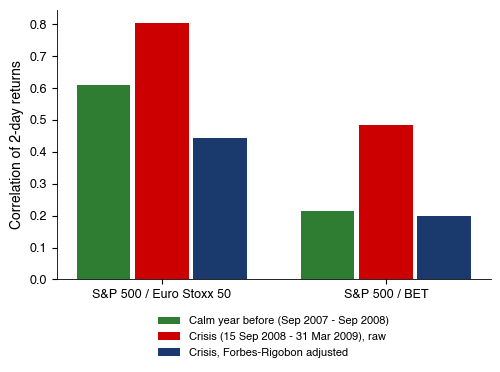

   saved ch6_forbes_rigobon


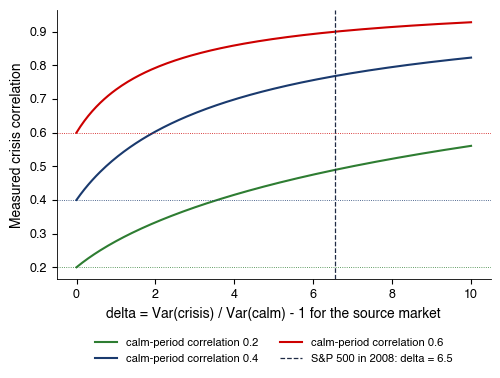

   saved ch6_fr_bias


In [7]:
fig_forbes_rigobon()
fig_fr_bias()

![ch6_fr_bias](./ch6_fr_bias.png)

Output: `ch6_fr_bias.pdf`